In [2]:
from pathlib import Path
import sys

SRC_ROOT = Path.cwd().resolve().parents[0]
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))


# Move two levels up: notebooks -> 01_src -> project root
PROJECT_ROOT = Path.cwd().resolve().parents[1]

PROCESSED_ROOT = PROJECT_ROOT / "02_processed_data"

TRAINING_ROOT = PROCESSED_ROOT / "training"
VALIDATION_ROOT = PROCESSED_ROOT / "validation"
TEST_ROOT = PROCESSED_ROOT / "test"

KNOWLEDGE_BASE_ROOT = PROCESSED_ROOT / "knowledge_base"

print("Current working directory:")
print(Path.cwd())

print("\nCorrected project root:")
print(PROJECT_ROOT)

print("\nProcessed data directory:")
print(PROCESSED_ROOT)

print("\nTraining directory exists:", TRAINING_ROOT.exists())
print("Validation directory exists:", VALIDATION_ROOT.exists())
print("Test directory exists:", TEST_ROOT.exists())
print("Knowledge base directory exists:", KNOWLEDGE_BASE_ROOT.exists())
from config.pipeline_config import (
    TRAINING_SIZE,
    VALIDATION_SIZE,
    TEST_SIZE,
    CAPTIONS_PER_IMAGE,
)

from config.pipeline_config import (
    load_saved_pipeline_snapshot,
    check_pipeline_compatibility,
)


Current working directory:
c:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\01_src\notebooks

Corrected project root:
C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG

Processed data directory:
C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data

Training directory exists: True
Validation directory exists: True
Test directory exists: True
Knowledge base directory exists: True


In [ ]:
from config.pipeline_config import PROCESSED_DATA

split_snapshot = load_saved_pipeline_snapshot()
check_pipeline_compatibility(split_snapshot, "Dataset release")

knowledge_base_metadata_file = (
    PROCESSED_DATA
    / "knowledge_base"
    / "metadata"
    / "knowledge_base_metadata.json"
)
with open(knowledge_base_metadata_file, "r", encoding="utf-8") as file:
    knowledge_base_metadata = json.load(file)

check_pipeline_compatibility(
    knowledge_base_metadata.get("pipeline_configuration"),
    "Knowledge-base metadata",
)
print("Configuration compatibility: PASSED")


In [3]:
from pathlib import Path

import json
import numpy as np
import faiss
import matplotlib.pyplot as plt
import pandas as pd

# Embedding files
CLIP_EMBEDDINGS_PATH = (
    TRAINING_ROOT / "embeddings" / "clip_image_embeddings.npy"
)
SBERT_EMBEDDINGS_PATH = (
    TRAINING_ROOT / "embeddings" / "sbert_caption_embeddings.npy"
)

CLIP_MAPPING_PATH = (
    TRAINING_ROOT / "embeddings" / "image_embedding_index.json"
)
SBERT_MAPPING_PATH = (
    TRAINING_ROOT / "embeddings" / "caption_embedding_index.json"
)

# FAISS indexes
CLIP_INDEX_PATH = (
    KNOWLEDGE_BASE_ROOT / "indexes" /
    "clip_image_index" / "clip_image_index.faiss"
)
SBERT_INDEX_PATH = (
    KNOWLEDGE_BASE_ROOT / "indexes" /
    "sbert_caption_index" / "sbert_caption_index.faiss"
)

# Knowledge-base documents
DOCUMENTS_DIR = KNOWLEDGE_BASE_ROOT / "documents"

IMAGE_DOCUMENTS_PATH = DOCUMENTS_DIR / "image_documents.json"
CAPTION_DOCUMENTS_PATH = DOCUMENTS_DIR / "caption_documents.json"

# Knowledge-base metadata and manifest
METADATA_DIR = KNOWLEDGE_BASE_ROOT / "metadata"
MANIFEST_DIR = KNOWLEDGE_BASE_ROOT / "manifest"

KNOWLEDGE_BASE_METADATA_PATH = (
    METADATA_DIR / "knowledge_base_metadata.json"
)
MANIFEST_PATH = MANIFEST_DIR / "knowledge_base_manifest.json"

# Verify required files
required_paths = [
    CLIP_EMBEDDINGS_PATH,
    SBERT_EMBEDDINGS_PATH,
    CLIP_MAPPING_PATH,
    SBERT_MAPPING_PATH,
    CLIP_INDEX_PATH,
    SBERT_INDEX_PATH,
    IMAGE_DOCUMENTS_PATH,
    CAPTION_DOCUMENTS_PATH,
    KNOWLEDGE_BASE_METADATA_PATH,
    MANIFEST_PATH
]

print("Checking knowledge-base artifacts...\n")

all_exist = True

for path in required_paths:
    exists = path.exists()
    print(f"{'OK' if exists else 'MISSING'}: {path.relative_to(PROJECT_ROOT)}")

    if not exists:
        all_exist = False

assert all_exist, "Some knowledge-base artifacts are missing."

print("\nAll required knowledge-base artifacts exist.")

Checking knowledge-base artifacts...

OK: 02_processed_data\training\embeddings\clip_image_embeddings.npy
OK: 02_processed_data\training\embeddings\sbert_caption_embeddings.npy
OK: 02_processed_data\training\embeddings\image_embedding_index.json
OK: 02_processed_data\training\embeddings\caption_embedding_index.json
OK: 02_processed_data\knowledge_base\indexes\clip_image_index\clip_image_index.faiss
OK: 02_processed_data\knowledge_base\indexes\sbert_caption_index\sbert_caption_index.faiss
OK: 02_processed_data\knowledge_base\documents\image_documents.json
OK: 02_processed_data\knowledge_base\documents\caption_documents.json
OK: 02_processed_data\knowledge_base\metadata\knowledge_base_metadata.json
OK: 02_processed_data\knowledge_base\manifest\knowledge_base_manifest.json

All required knowledge-base artifacts exist.


In [4]:
# Load embedding matrices
clip_embeddings = np.load(CLIP_EMBEDDINGS_PATH)
sbert_embeddings = np.load(SBERT_EMBEDDINGS_PATH)

# Load embedding mappings
with open(CLIP_MAPPING_PATH, "r", encoding="utf-8") as f:
    clip_mapping = json.load(f)

with open(SBERT_MAPPING_PATH, "r", encoding="utf-8") as f:
    sbert_mapping = json.load(f)


def check_embedding_integrity(
    name,
    embeddings,
    mapping,
    expected_count,
    expected_dimension
):
    print(f"\n{'=' * 55}")
    print(f"{name} EMBEDDING QUALITY CONTROL")
    print(f"{'=' * 55}")

    print("Shape:", embeddings.shape)
    print("Data type:", embeddings.dtype)
    print("Mapping records:", len(mapping))

    # Check dimensions
    assert embeddings.ndim == 2, "Embedding matrix must be 2D."
    assert embeddings.shape == (
        expected_count,
        expected_dimension
    ), "Unexpected embedding dimensions or count."

    # Check data type
    assert embeddings.dtype == np.float32, "Expected float32."

    # Check mapping count
    assert len(mapping) == expected_count, "Mapping count mismatch."

    # Check NaN and infinity
    nan_count = int(np.isnan(embeddings).sum())
    inf_count = int(np.isinf(embeddings).sum())

    print("NaN values:", nan_count)
    print("Infinite values:", inf_count)

    assert nan_count == 0, "NaN values detected."
    assert inf_count == 0, "Infinite values detected."

    # Check zero vectors
    norms = np.linalg.norm(embeddings, axis=1)
    zero_vectors = int(np.sum(norms == 0))

    print("Zero vectors:", zero_vectors)
    print("Minimum vector norm:", float(norms.min()))
    print("Maximum vector norm:", float(norms.max()))

    assert zero_vectors == 0, "Zero vectors detected."

    print(f"\n{name} integrity: PASSED")


# CLIP: one embedding per training image
check_embedding_integrity(
    name="CLIP",
    embeddings=clip_embeddings,
    mapping=clip_mapping,
    expected_count=TRAINING_SIZE,
    expected_dimension=512
)

# SBERT: one embedding per training caption
check_embedding_integrity(
    name="SBERT",
    embeddings=sbert_embeddings,
    mapping=sbert_mapping,
    expected_count=TRAINING_SIZE * CAPTIONS_PER_IMAGE,
    expected_dimension=384
)

print("\nEmbedding integrity checks: ALL PASSED")


CLIP EMBEDDING QUALITY CONTROL
Shape: (9900, 512)
Data type: float32
Mapping records: 9900
NaN values: 0
Infinite values: 0
Zero vectors: 0
Minimum vector norm: 0.9999997019767761
Maximum vector norm: 1.000000238418579

CLIP integrity: PASSED

SBERT EMBEDDING QUALITY CONTROL
Shape: (49500, 384)
Data type: float32
Mapping records: 49500
NaN values: 0
Infinite values: 0
Zero vectors: 0
Minimum vector norm: 0.9999998807907104
Maximum vector norm: 1.0000001192092896

SBERT integrity: PASSED

Embedding integrity checks: ALL PASSED


In [5]:
def check_mapping_duplicates(name, mapping, id_field):
    ids = [record[id_field] for record in mapping]

    duplicate_ids = len(ids) - len(set(ids))
    missing_ids = sum(
        1 for value in ids
        if value is None
    )

    incorrect_rows = [
        i for i, record in enumerate(mapping)
        if record.get("row") != i
    ]

    print(f"\n{name} mapping:")
    print("Total records:", len(mapping))
    print("Unique IDs:", len(set(ids)))
    print("Duplicate IDs:", duplicate_ids)
    print("Missing IDs:", missing_ids)
    print("Incorrect row positions:", len(incorrect_rows))

    assert duplicate_ids == 0, "Duplicate IDs detected."
    assert missing_ids == 0, "Missing IDs detected."
    assert len(incorrect_rows) == 0, "Incorrect row positions."

    print(f"{name} mapping: PASSED")


check_mapping_duplicates(
    "CLIP",
    clip_mapping,
    "image_id"
)

check_mapping_duplicates(
    "SBERT",
    sbert_mapping,
    "caption_id"
)

# Check that every SBERT caption has an image association
missing_image_ids = sum(
    1 for record in sbert_mapping
    if record.get("image_id") is None
)

print("\nSBERT missing image associations:", missing_image_ids)

assert missing_image_ids == 0

print("\nMapping duplicate checks: ALL PASSED")


CLIP mapping:
Total records: 9900
Unique IDs: 9900
Duplicate IDs: 0
Missing IDs: 0
Incorrect row positions: 0
CLIP mapping: PASSED

SBERT mapping:
Total records: 49500
Unique IDs: 49500
Duplicate IDs: 0
Missing IDs: 0
Incorrect row positions: 0
SBERT mapping: PASSED

SBERT missing image associations: 0

Mapping duplicate checks: ALL PASSED


In [8]:
# Create lookup dictionaries
image_docs_by_id = {
    doc["image_id"]: doc
    for doc in image_documents
}

caption_docs_by_id = {
    doc["caption_id"]: doc
    for doc in caption_documents
}

# --------------------------------------------------
# 1. Check CLIP mapping against image documents
# --------------------------------------------------

clip_mismatches = []

for record in clip_mapping:
    image_id = record["image_id"]
    row = record["row"]

    doc = image_docs_by_id.get(image_id)

    if doc is None:
        clip_mismatches.append(
            f"Image {image_id}: missing document"
        )
        continue

    if doc["embedding"]["row"] != row:
        clip_mismatches.append(
            f"Image {image_id}: embedding row mismatch"
        )

# --------------------------------------------------
# 2. Check SBERT mapping against caption documents
# --------------------------------------------------

sbert_mismatches = []

for record in sbert_mapping:
    caption_id = record["caption_id"]
    image_id = record["image_id"]
    row = record["row"]

    doc = caption_docs_by_id.get(caption_id)

    if doc is None:
        sbert_mismatches.append(
            f"Caption {caption_id}: missing document"
        )
        continue

    if doc["image_id"] != image_id:
        sbert_mismatches.append(
            f"Caption {caption_id}: image association mismatch"
        )

    if doc["embedding"]["row"] != row:
        sbert_mismatches.append(
            f"Caption {caption_id}: embedding row mismatch"
        )

# --------------------------------------------------
# 3. Display results
# --------------------------------------------------

print("CLIP document mismatches:", len(clip_mismatches))
print("SBERT document mismatches:", len(sbert_mismatches))

if clip_mismatches:
    print("\nCLIP examples:", clip_mismatches[:5])

if sbert_mismatches:
    print("\nSBERT examples:", sbert_mismatches[:5])

assert len(clip_mismatches) == 0
assert len(sbert_mismatches) == 0

print("\nEmbedding-to-document consistency: PASSED")

CLIP document mismatches: 0
SBERT document mismatches: 0

Embedding-to-document consistency: PASSED


In [9]:
# Build a mapping: image_id -> caption IDs
image_to_captions = {
    doc["image_id"]: doc["caption_ids"]
    for doc in image_documents
}

# Track all caption references
all_referenced_caption_ids = []

relationship_errors = []

for image_id, caption_ids in image_to_captions.items():

    # Check exactly five captions per image
    if len(caption_ids) != CAPTIONS_PER_IMAGE:
        relationship_errors.append(
            f"Image {image_id}: expected {CAPTIONS_PER_IMAGE} captions, found {len(caption_ids)}"
        )

    # Check duplicate caption IDs within an image
    if len(caption_ids) != len(set(caption_ids)):
        relationship_errors.append(
            f"Image {image_id}: duplicate caption IDs"
        )

    for caption_id in caption_ids:
        all_referenced_caption_ids.append(caption_id)

        caption_doc = caption_docs_by_id.get(caption_id)

        if caption_doc is None:
            relationship_errors.append(
                f"Image {image_id}: caption {caption_id} is missing"
            )
            continue

        # Check caption belongs to the correct image
        if caption_doc["image_id"] != image_id:
            relationship_errors.append(
                f"Caption {caption_id}: belongs to another image"
            )

# Check that all caption documents are referenced
all_caption_ids = set(caption_docs_by_id.keys())
referenced_caption_ids = set(all_referenced_caption_ids)

unreferenced_captions = (
    all_caption_ids - referenced_caption_ids
)

# Check for captions referenced by multiple images
duplicate_references = (
    len(all_referenced_caption_ids)
    - len(referenced_caption_ids)
)

print("Image documents:", len(image_documents))
print("Caption documents:", len(caption_documents))
print("Total caption references:", len(all_referenced_caption_ids))
print("Unique referenced captions:", len(referenced_caption_ids))
print("Unreferenced captions:", len(unreferenced_captions))
print("Duplicate references:", duplicate_references)
print("Relationship errors:", len(relationship_errors))

if relationship_errors:
    print("\nExamples:", relationship_errors[:10])

assert len(relationship_errors) == 0
assert len(unreferenced_captions) == 0
assert duplicate_references == 0
assert len(referenced_caption_ids) == TRAINING_SIZE * CAPTIONS_PER_IMAGE

print("\nImage-caption relationship checks: PASSED")

Image documents: 9900
Caption documents: 49500
Total caption references: 49500
Unique referenced captions: 49500
Unreferenced captions: 0
Duplicate references: 0
Relationship errors: 0

Image-caption relationship checks: PASSED


In [10]:
# --------------------------------------------------
# 1. Load the original split IDs
# --------------------------------------------------

SPLITS_DIR = PROCESSED_ROOT / "splits"

with open(SPLITS_DIR / "training_ids.json", "r", encoding="utf-8") as f:
    training_ids = json.load(f)

with open(SPLITS_DIR / "validation_ids.json", "r", encoding="utf-8") as f:
    validation_ids = json.load(f)

with open(SPLITS_DIR / "test_ids.json", "r", encoding="utf-8") as f:
    test_ids = json.load(f)


# Convert to sets for comparison
training_set = set(training_ids)
validation_set = set(validation_ids)
test_set = set(test_ids)


# --------------------------------------------------
# 2. Check split sizes and duplicate IDs
# --------------------------------------------------

print("SPLIT COUNTS")
print("Training:", len(training_ids))
print("Validation:", len(validation_ids))
print("Test:", len(test_ids))

assert len(training_ids) == TRAINING_SIZE
assert len(validation_ids) == VALIDATION_SIZE
assert len(test_ids) == TEST_SIZE

assert len(training_set) == len(training_ids), "Duplicate training IDs."
assert len(validation_set) == len(validation_ids), "Duplicate validation IDs."
assert len(test_set) == len(test_ids), "Duplicate test IDs."


# --------------------------------------------------
# 3. Check that splits are mutually exclusive
# --------------------------------------------------

training_validation_overlap = training_set & validation_set
training_test_overlap = training_set & test_set
validation_test_overlap = validation_set & test_set

print("\nSPLIT OVERLAP")
print("Training-validation:", len(training_validation_overlap))
print("Training-test:", len(training_test_overlap))
print("Validation-test:", len(validation_test_overlap))

assert len(training_validation_overlap) == 0
assert len(training_test_overlap) == 0
assert len(validation_test_overlap) == 0


# --------------------------------------------------
# 4. Check knowledge-base image membership
# --------------------------------------------------

kb_image_ids = {
    doc["image_id"]
    for doc in image_documents
}

kb_validation_overlap = kb_image_ids & validation_set
kb_test_overlap = kb_image_ids & test_set
kb_non_training_ids = kb_image_ids - training_set

print("\nKNOWLEDGE-BASE LEAKAGE CHECK")
print("KB image count:", len(kb_image_ids))
print("Validation images in KB:", len(kb_validation_overlap))
print("Test images in KB:", len(kb_test_overlap))
print("KB images outside training split:", len(kb_non_training_ids))

assert kb_image_ids == training_set
assert len(kb_validation_overlap) == 0
assert len(kb_test_overlap) == 0
assert len(kb_non_training_ids) == 0


# --------------------------------------------------
# 5. Check caption membership
# --------------------------------------------------

kb_caption_image_ids = {
    doc["image_id"]
    for doc in caption_documents
}

caption_non_training_ids = kb_caption_image_ids - training_set

print("\nCAPTION LEAKAGE CHECK")
print("Unique images referenced by captions:", len(kb_caption_image_ids))
print("Caption documents referencing non-training images:",
      len(caption_non_training_ids))

assert kb_caption_image_ids.issubset(training_set)
assert len(caption_non_training_ids) == 0


# --------------------------------------------------
# 6. Final result
# --------------------------------------------------

print("\nDATASET LEAKAGE AUDIT: PASSED")

SPLIT COUNTS
Training: 9900
Validation: 100
Test: 100

SPLIT OVERLAP
Training-validation: 0
Training-test: 0
Validation-test: 0

KNOWLEDGE-BASE LEAKAGE CHECK
KB image count: 9900
Validation images in KB: 0
Test images in KB: 0
KB images outside training split: 0

CAPTION LEAKAGE CHECK
Unique images referenced by captions: 9900
Caption documents referencing non-training images: 0

DATASET LEAKAGE AUDIT: PASSED


In [11]:
# Load FAISS indexes
clip_index = faiss.read_index(str(CLIP_INDEX_PATH))
sbert_index = faiss.read_index(str(SBERT_INDEX_PATH))


def check_faiss_index(
    name,
    index,
    embeddings,
    expected_count,
    expected_dimension
):
    print(f"\n{'=' * 55}")
    print(f"{name} FAISS INDEX QC")
    print(f"{'=' * 55}")

    print("Index dimension:", index.d)
    print("Index vector count:", index.ntotal)
    print("Expected vector count:", expected_count)
    print("Index metric:", index.metric_type)

    assert index.d == expected_dimension
    assert index.ntotal == expected_count
    assert index.ntotal == embeddings.shape[0]
    assert index.metric_type == faiss.METRIC_INNER_PRODUCT

    # Verify stored vectors against original embeddings
    stored_vectors = index.reconstruct_n(
        0,
        index.ntotal
    )

    vectors_match = np.allclose(
        stored_vectors,
        embeddings,
        rtol=1e-5,
        atol=1e-6
    )

    print("Stored vectors match original embeddings:", vectors_match)

    assert vectors_match, "FAISS vectors differ from original embeddings."

    print(f"\n{name} FAISS index: PASSED")


# CLIP image index
check_faiss_index(
    name="CLIP",
    index=clip_index,
    embeddings=clip_embeddings,
    expected_count=TRAINING_SIZE,
    expected_dimension=512
)

# SBERT caption index
check_faiss_index(
    name="SBERT",
    index=sbert_index,
    embeddings=sbert_embeddings,
    expected_count=TRAINING_SIZE * CAPTIONS_PER_IMAGE,
    expected_dimension=384
)

print("\nFAISS INDEX INTEGRITY: ALL PASSED")


CLIP FAISS INDEX QC
Index dimension: 512
Index vector count: 9900
Expected vector count: 9900
Index metric: 0
Stored vectors match original embeddings: True

CLIP FAISS index: PASSED

SBERT FAISS INDEX QC
Index dimension: 384
Index vector count: 49500
Expected vector count: 49500
Index metric: 0
Stored vectors match original embeddings: True

SBERT FAISS index: PASSED

FAISS INDEX INTEGRITY: ALL PASSED


In [12]:
# Load metadata and manifest
with open(KNOWLEDGE_BASE_METADATA_PATH, "r", encoding="utf-8") as f:
    kb_metadata = json.load(f)

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    kb_manifest = json.load(f)

print("KNOWLEDGE-BASE METADATA")
print("Top-level fields:", list(kb_metadata.keys()))

print("\nKNOWLEDGE-BASE MANIFEST")
print("Top-level fields:", list(kb_manifest.keys()))

print("\nManifest structure:")
print(json.dumps(kb_manifest, indent=4)[:5000])

print("\nMetadata structure:")
print(json.dumps(kb_metadata, indent=4)[:5000])

KNOWLEDGE-BASE METADATA
Top-level fields: ['metadata_version', 'knowledge_base', 'indexes', 'documents', 'relationships', 'data_exclusion', 'construction_date_utc', 'construction_status']

KNOWLEDGE-BASE MANIFEST
Top-level fields: ['manifest_version', 'knowledge_base', 'dataset', 'split', 'statistics', 'files', 'excluded_data', 'generated_at_utc', 'status']

Manifest structure:
{
    "manifest_version": "1.0",
    "knowledge_base": "MS-COCO Image Captioning Knowledge Base",
    "dataset": "MS-COCO 2017",
    "split": "training",
    "statistics": {
        "image_count": 9900,
        "caption_count": 49500,
        "clip_vector_count": 9900,
        "sbert_vector_count": 49500,
        "total_indexed_vectors": 59400
    },
    "files": [
        {
            "name": "CLIP FAISS index",
            "path": "indexes/clip_image_index/clip_image_index.faiss",
            "type": "FAISS index",
            "records": 9900,
            "file_size_bytes": 20275245
        },
        {
     

In [13]:
# --------------------------------------------------
# 1. Validate metadata status and dataset information
# --------------------------------------------------

assert kb_metadata["construction_status"] == "completed"
assert kb_manifest["status"] == "completed"

kb_info = kb_metadata["knowledge_base"]

assert kb_info["dataset"] == "MS-COCO 2017"
assert kb_info["split"] == "training"
assert kb_info["random_seed"] == 45
assert kb_info["image_count"] == TRAINING_SIZE
assert kb_info["caption_count"] == TRAINING_SIZE * CAPTIONS_PER_IMAGE
assert kb_info["captions_per_image"] == 5

print("Knowledge-base metadata: PASSED")


# --------------------------------------------------
# 2. Validate index metadata
# --------------------------------------------------

clip_meta = kb_metadata["indexes"]["clip_image_index"]
sbert_meta = kb_metadata["indexes"]["sbert_caption_index"]

assert clip_meta["vector_count"] == clip_index.ntotal
assert clip_meta["dimension"] == clip_index.d
assert clip_meta["index_type"] == "IndexFlatIP"
assert clip_meta["normalized_embeddings"] is True

assert sbert_meta["vector_count"] == sbert_index.ntotal
assert sbert_meta["dimension"] == sbert_index.d
assert sbert_meta["index_type"] == "IndexFlatIP"
assert sbert_meta["normalized_embeddings"] is True

print("Index metadata: PASSED")


# --------------------------------------------------
# 3. Validate document metadata
# --------------------------------------------------

image_meta = kb_metadata["documents"]["image_documents"]
caption_meta = kb_metadata["documents"]["caption_documents"]

assert image_meta["count"] == len(image_documents)
assert caption_meta["count"] == len(caption_documents)

print("Document metadata: PASSED")


# --------------------------------------------------
# 4. Validate exclusion of validation and test data
# --------------------------------------------------

exclusion = kb_metadata["data_exclusion"]

assert exclusion["validation_included"] is False
assert exclusion["test_included"] is False

assert "validation" in kb_manifest["excluded_data"]
assert "test" in kb_manifest["excluded_data"]

print("Data exclusion metadata: PASSED")


# --------------------------------------------------
# 5. Validate manifest statistics
# --------------------------------------------------

stats = kb_manifest["statistics"]

assert stats["image_count"] == len(image_documents)
assert stats["caption_count"] == len(caption_documents)
assert stats["clip_vector_count"] == clip_index.ntotal
assert stats["sbert_vector_count"] == sbert_index.ntotal

assert stats["total_indexed_vectors"] == (
    clip_index.ntotal + sbert_index.ntotal
)

print("Manifest statistics: PASSED")


# --------------------------------------------------
# 6. Validate manifest file inventory
# --------------------------------------------------

manifest_files = kb_manifest["files"]

assert len(manifest_files) == 5

for item in manifest_files:
    artifact_path = KNOWLEDGE_BASE_ROOT / item["path"]

    assert artifact_path.exists(), (
        f"Missing artifact: {item['path']}"
    )

    actual_size = artifact_path.stat().st_size

    assert actual_size == item["file_size_bytes"], (
        f"File size mismatch: {item['path']}"
    )

    if item["records"] is not None:
        assert actual_size > 0

print("Manifest file inventory and sizes: PASSED")


# --------------------------------------------------
# 7. Final result
# --------------------------------------------------

print("\nMETADATA AND MANIFEST QC: ALL PASSED")

Knowledge-base metadata: PASSED
Index metadata: PASSED
Document metadata: PASSED
Data exclusion metadata: PASSED
Manifest statistics: PASSED
Manifest file inventory and sizes: PASSED

METADATA AND MANIFEST QC: ALL PASSED


In [14]:
# Locate existing statistical exploration outputs

ANALYSIS_ROOT = PROJECT_ROOT / "03_analysis"

for path in sorted(ANALYSIS_ROOT.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))

03_analysis\01_statistical_exploration\outputs\figures\caption_length_distribution.png
03_analysis\01_statistical_exploration\outputs\figures\colour_mentions.png
03_analysis\01_statistical_exploration\outputs\figures\context_mentions.png
03_analysis\01_statistical_exploration\outputs\figures\object_cooccurrence_heatmap.png
03_analysis\01_statistical_exploration\outputs\figures\objects_per_image_distribution.png
03_analysis\01_statistical_exploration\outputs\figures\pos_distribution.png
03_analysis\01_statistical_exploration\outputs\figures\shape_mentions.png
03_analysis\01_statistical_exploration\outputs\figures\top_30_frequent_words.png
03_analysis\01_statistical_exploration\outputs\figures\top_50_object_classes.png
03_analysis\01_statistical_exploration\outputs\statistics\caption_length_statistics.csv
03_analysis\01_statistical_exploration\outputs\statistics\caption_length_statistics.json
03_analysis\01_statistical_exploration\outputs\statistics\diversity_statistics.json
03_analysis\

In [15]:
# Statistical exploration output directories
STAT_ROOT = (
    PROJECT_ROOT
    / "03_analysis"
    / "01_statistical_exploration"
    / "outputs"
)

FIGURES_DIR = STAT_ROOT / "figures"
TABLES_DIR = STAT_ROOT / "tables"
STATISTICS_DIR = STAT_ROOT / "statistics"

# Required figures
required_figures = [
    "top_50_object_classes.png",
    "objects_per_image_distribution.png",
    "caption_length_distribution.png",
    "top_30_frequent_words.png",
    "pos_distribution.png",
]

# Required statistical JSON files
required_statistics = [
    "scene_complexity_statistics.json",
    "caption_length_statistics.json",
    "vocabulary_statistics.json",
    "pos_statistics.json",
    "diversity_statistics.json",
]

# Required tables
required_tables = [
    "object_class_frequency.csv",
    "objects_per_image_distribution.csv",
    "caption_lengths.csv",
    "pos_distribution.csv",
]

# --------------------------------------------------
# 1. Verify figures
# --------------------------------------------------

from PIL import Image

print("FIGURE VERIFICATION")

for filename in required_figures:
    path = FIGURES_DIR / filename

    assert path.exists(), f"Missing figure: {filename}"

    with Image.open(path) as img:
        img.verify()

    print(f"OK: {filename}")

# --------------------------------------------------
# 2. Verify statistical JSON files
# --------------------------------------------------

print("\nSTATISTICS VERIFICATION")

for filename in required_statistics:
    path = STATISTICS_DIR / filename

    assert path.exists(), f"Missing statistics file: {filename}"

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    assert isinstance(data, dict), (
        f"Unexpected JSON structure: {filename}"
    )

    assert len(data) > 0, (
        f"Empty statistics file: {filename}"
    )

    print(f"OK: {filename}")

# --------------------------------------------------
# 3. Verify CSV tables
# --------------------------------------------------

print("\nTABLE VERIFICATION")

for filename in required_tables:
    path = TABLES_DIR / filename

    assert path.exists(), f"Missing table: {filename}"

    df = pd.read_csv(path)

    assert not df.empty, f"Empty table: {filename}"

    print(
        f"OK: {filename} "
        f"({len(df)} rows, {len(df.columns)} columns)"
    )

print("\nSTATISTICAL QC ARTIFACT VERIFICATION: PASSED")

FIGURE VERIFICATION
OK: top_50_object_classes.png
OK: objects_per_image_distribution.png
OK: caption_length_distribution.png
OK: top_30_frequent_words.png
OK: pos_distribution.png

STATISTICS VERIFICATION
OK: scene_complexity_statistics.json
OK: caption_length_statistics.json
OK: vocabulary_statistics.json
OK: pos_statistics.json
OK: diversity_statistics.json

TABLE VERIFICATION
OK: object_class_frequency.csv (80 rows, 4 columns)
OK: objects_per_image_distribution.csv (54 rows, 3 columns)
OK: caption_lengths.csv (49500 rows, 2 columns)
OK: pos_distribution.csv (16 rows, 3 columns)

STATISTICAL QC ARTIFACT VERIFICATION: PASSED



Figure: top_50_object_classes.png


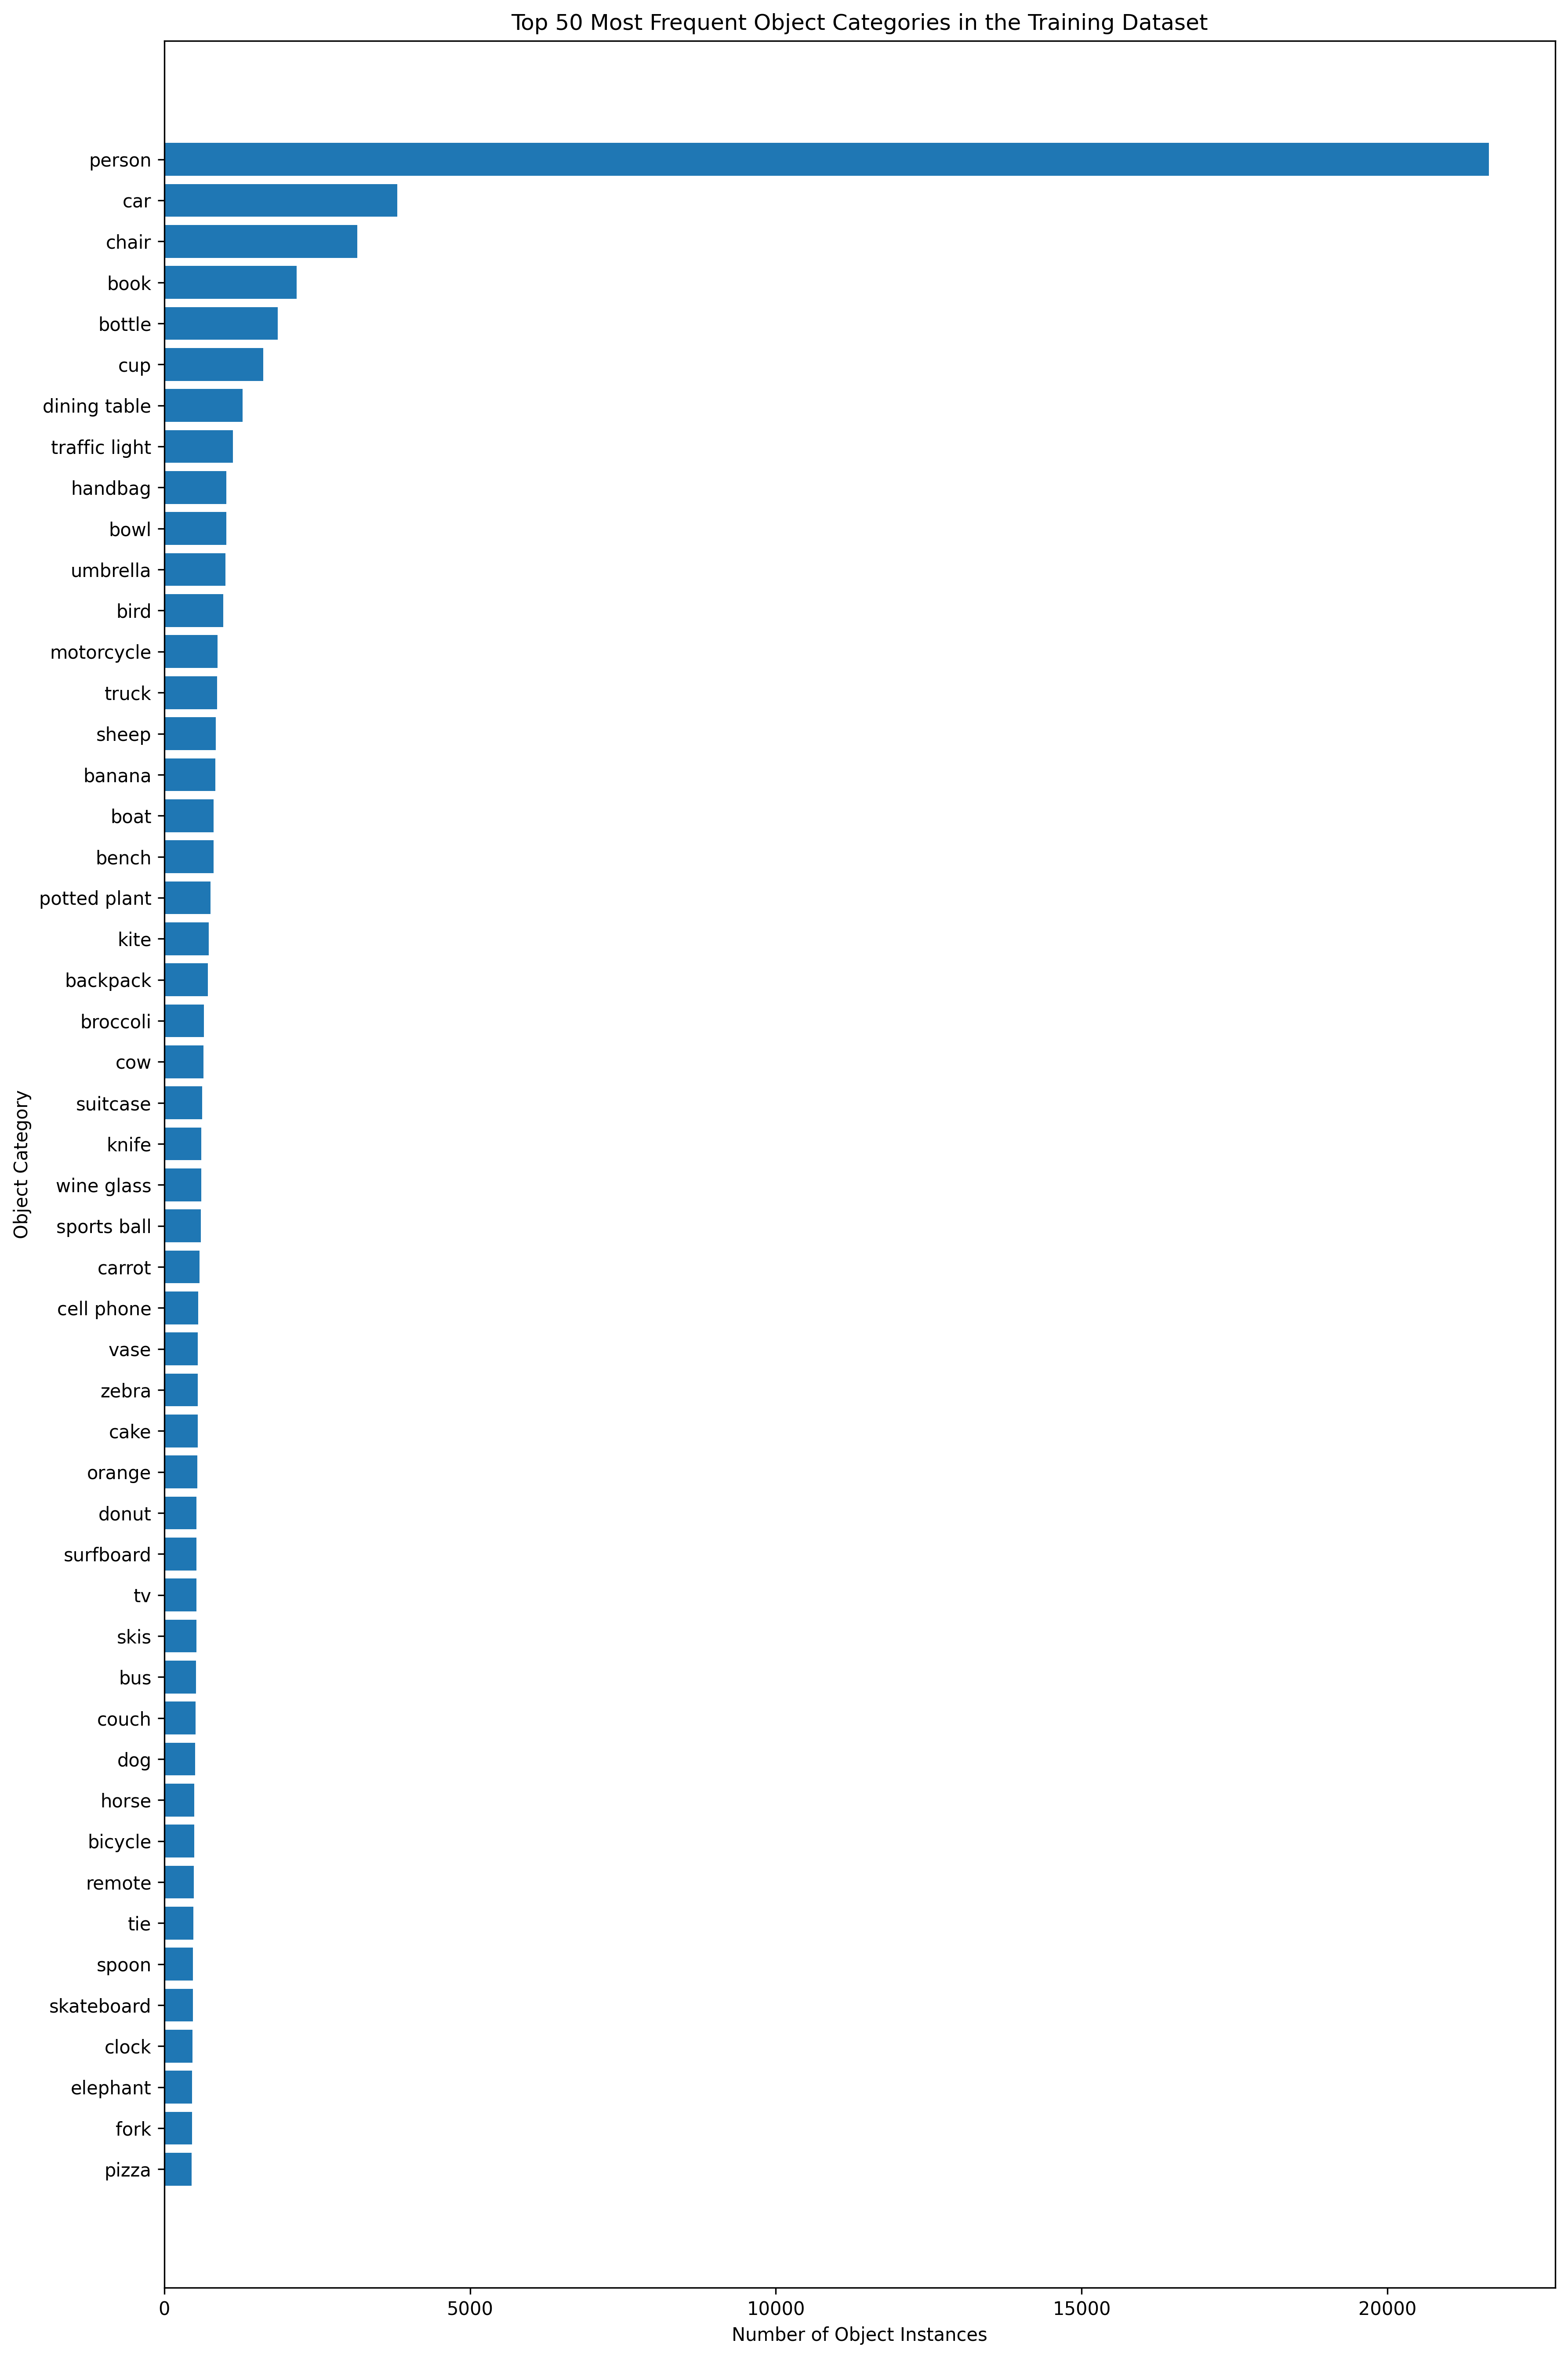


Figure: objects_per_image_distribution.png


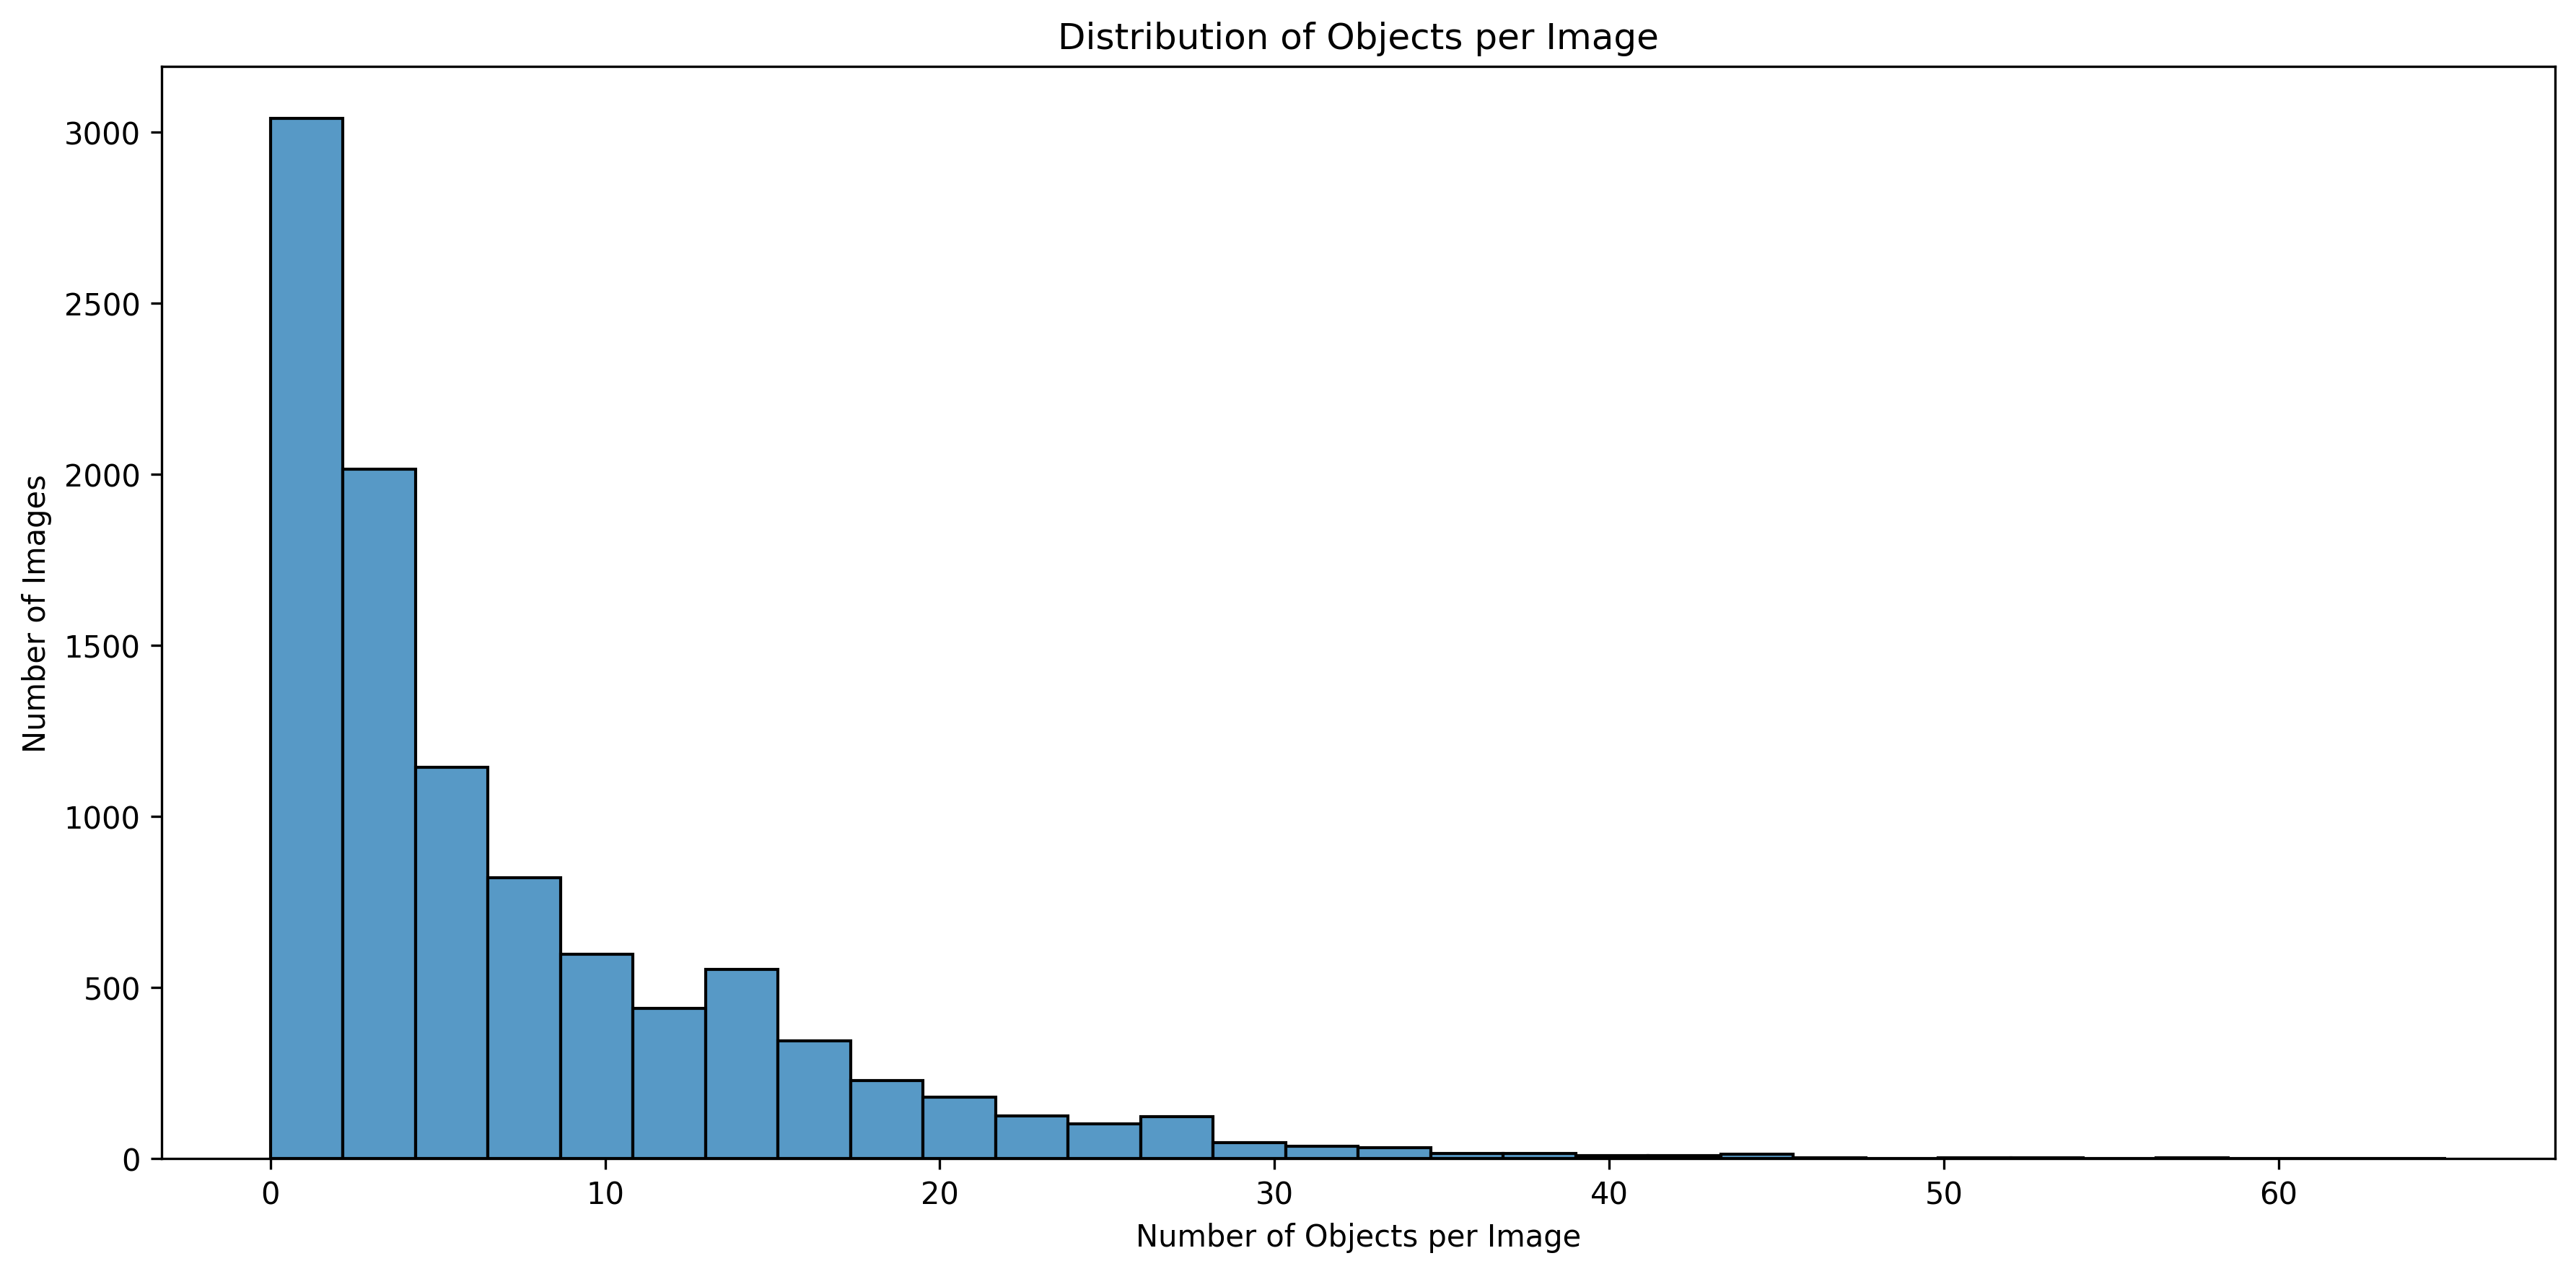


Figure: caption_length_distribution.png


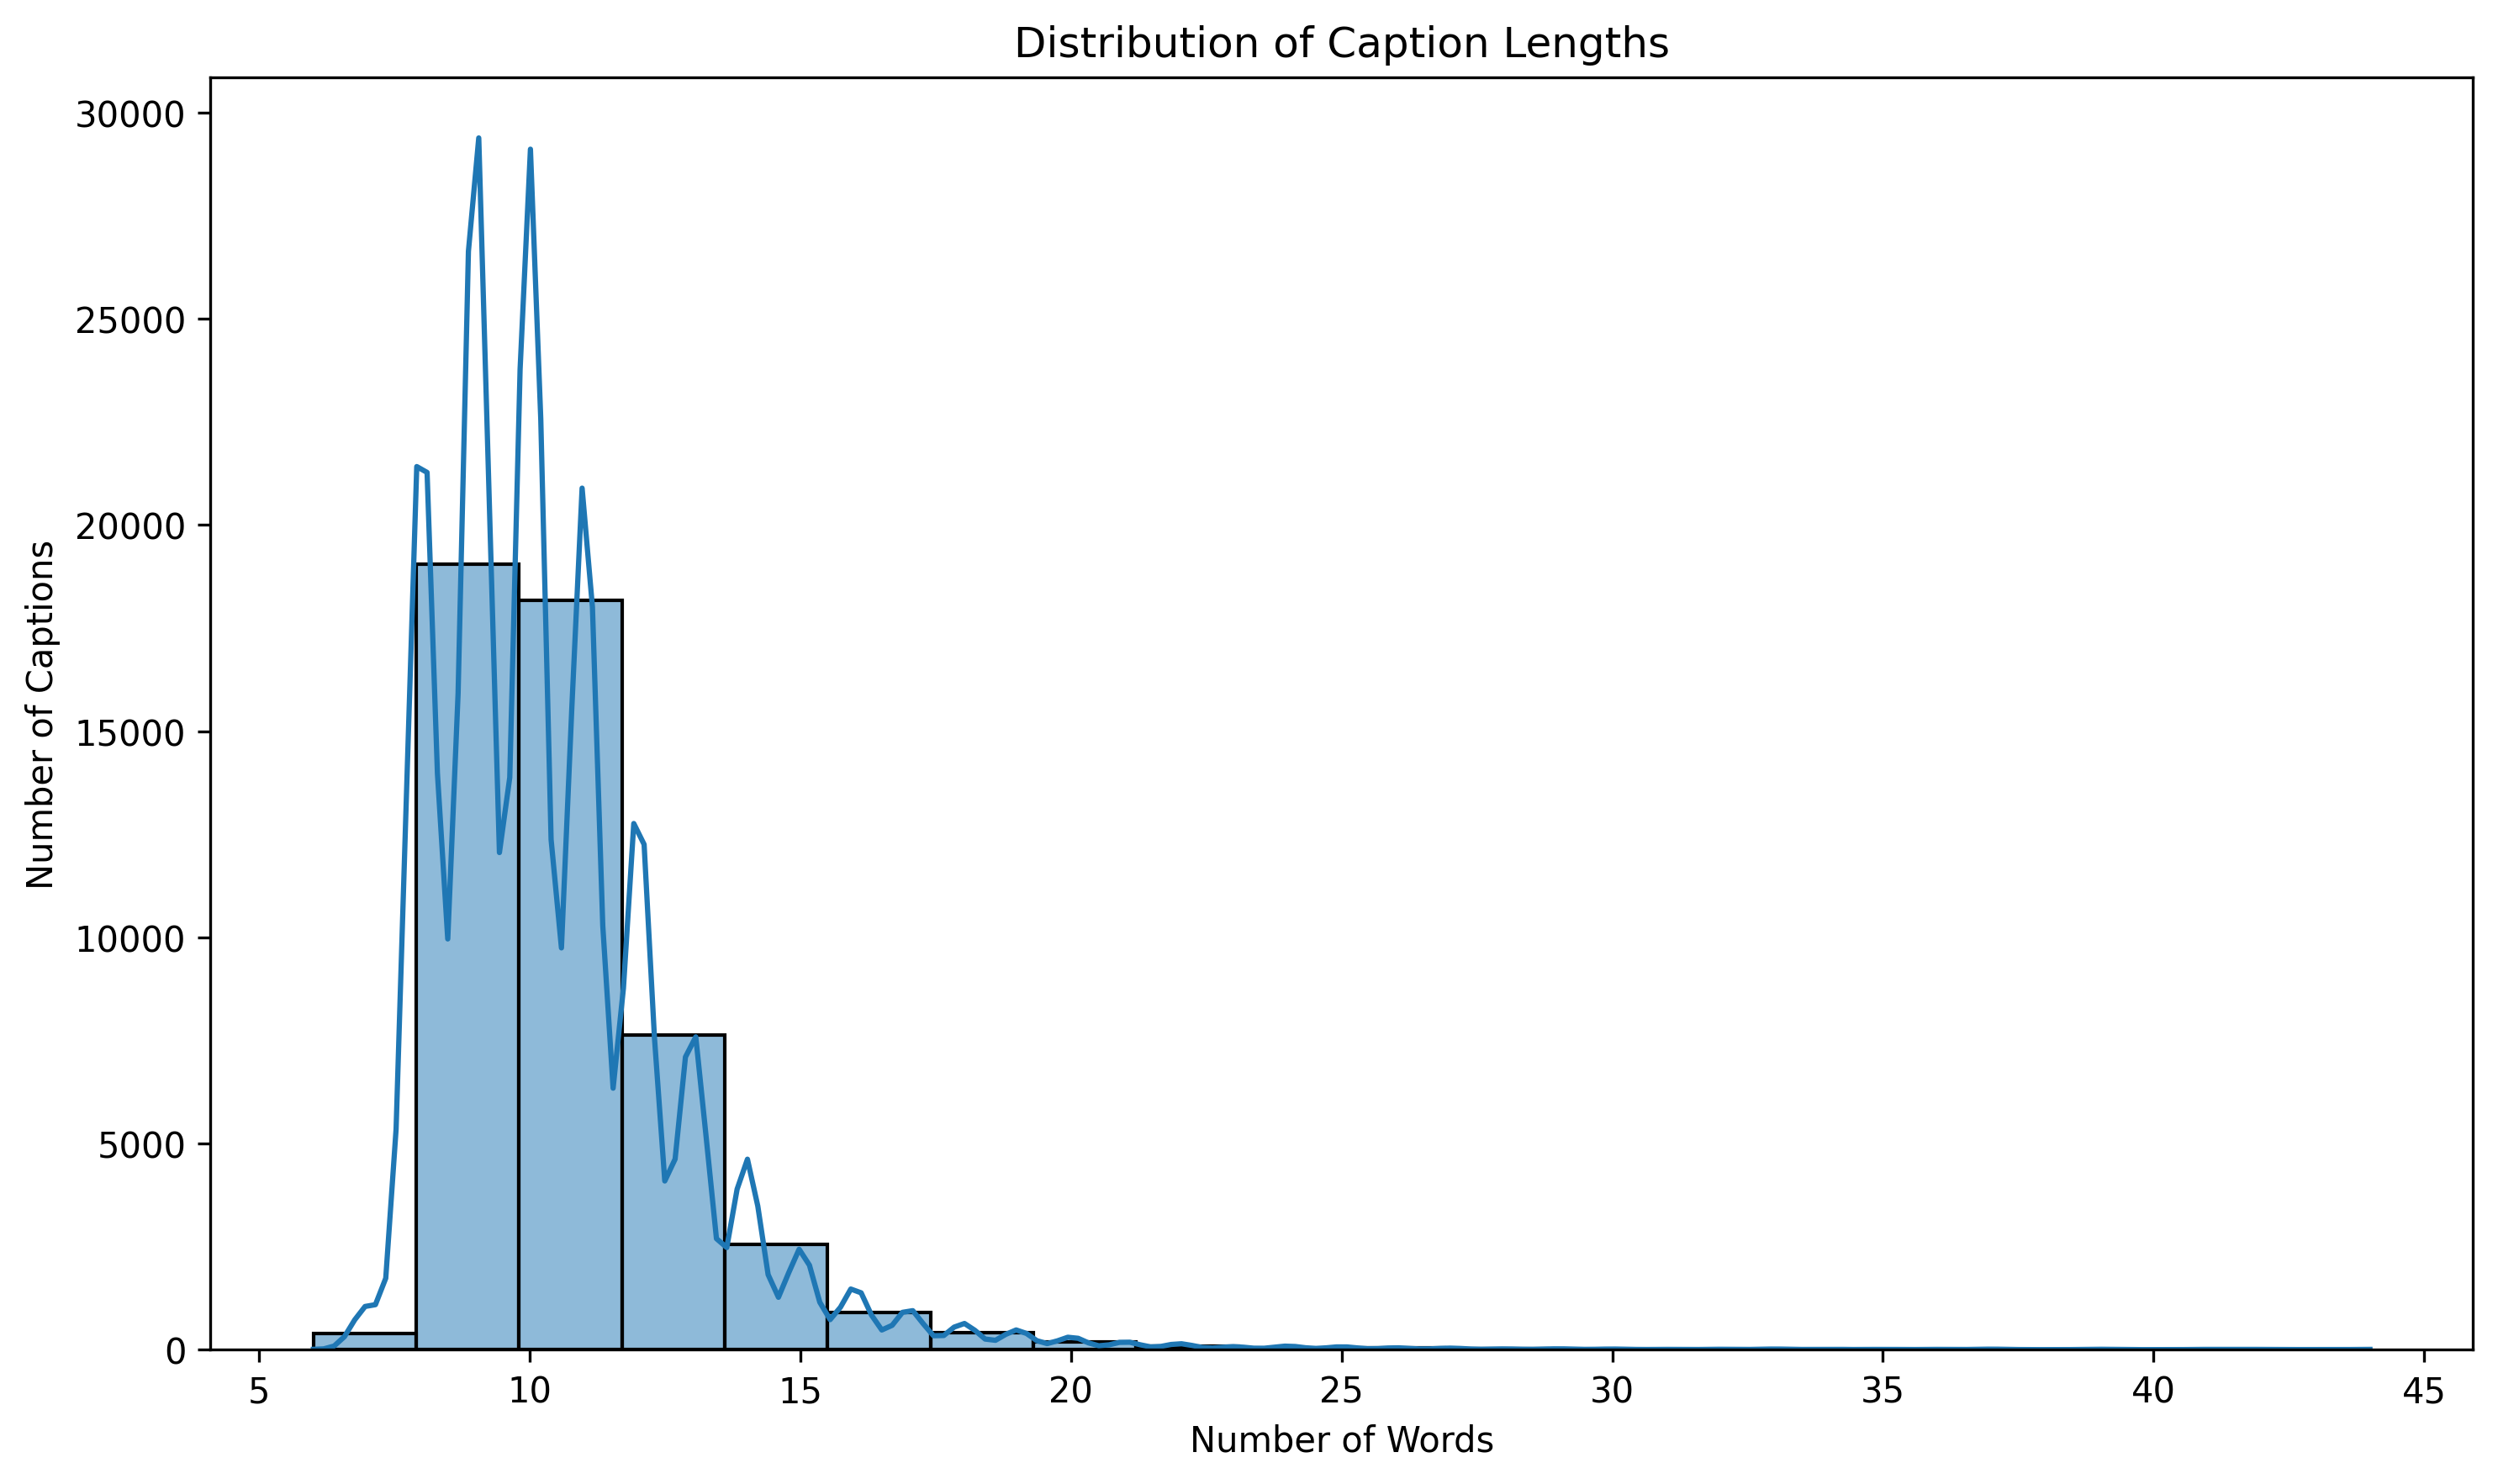


Figure: top_30_frequent_words.png


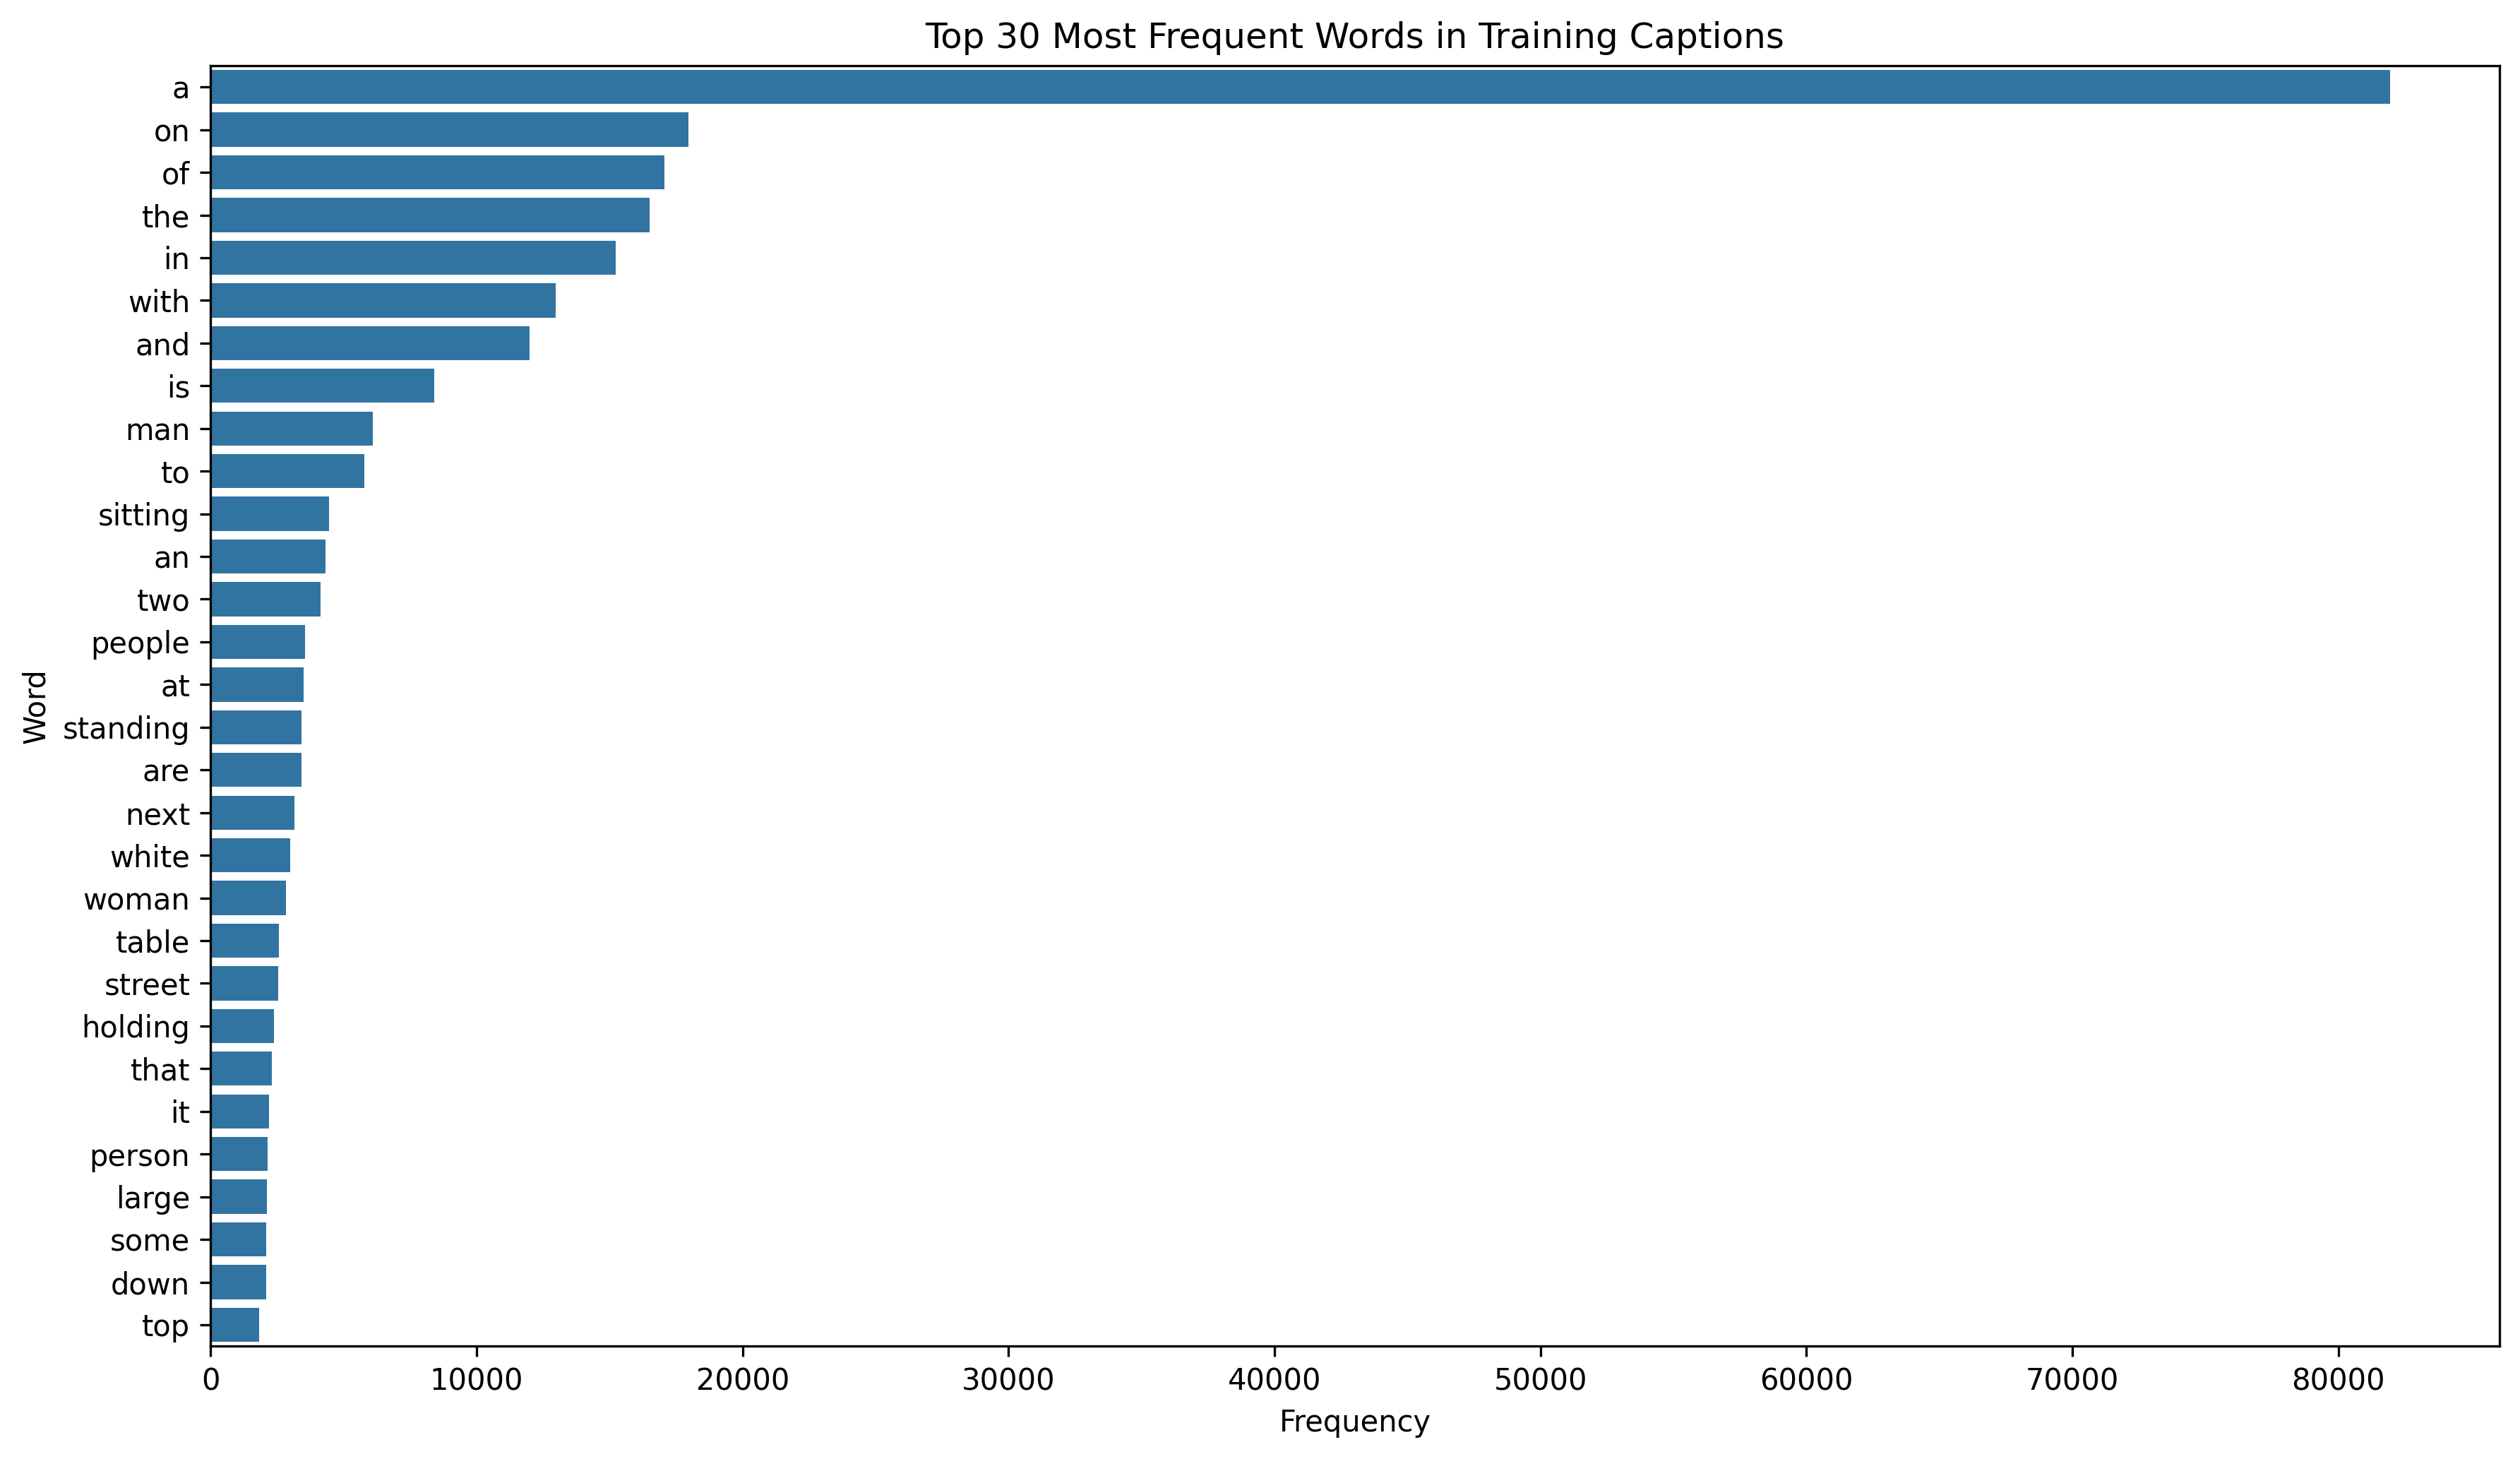


Figure: pos_distribution.png


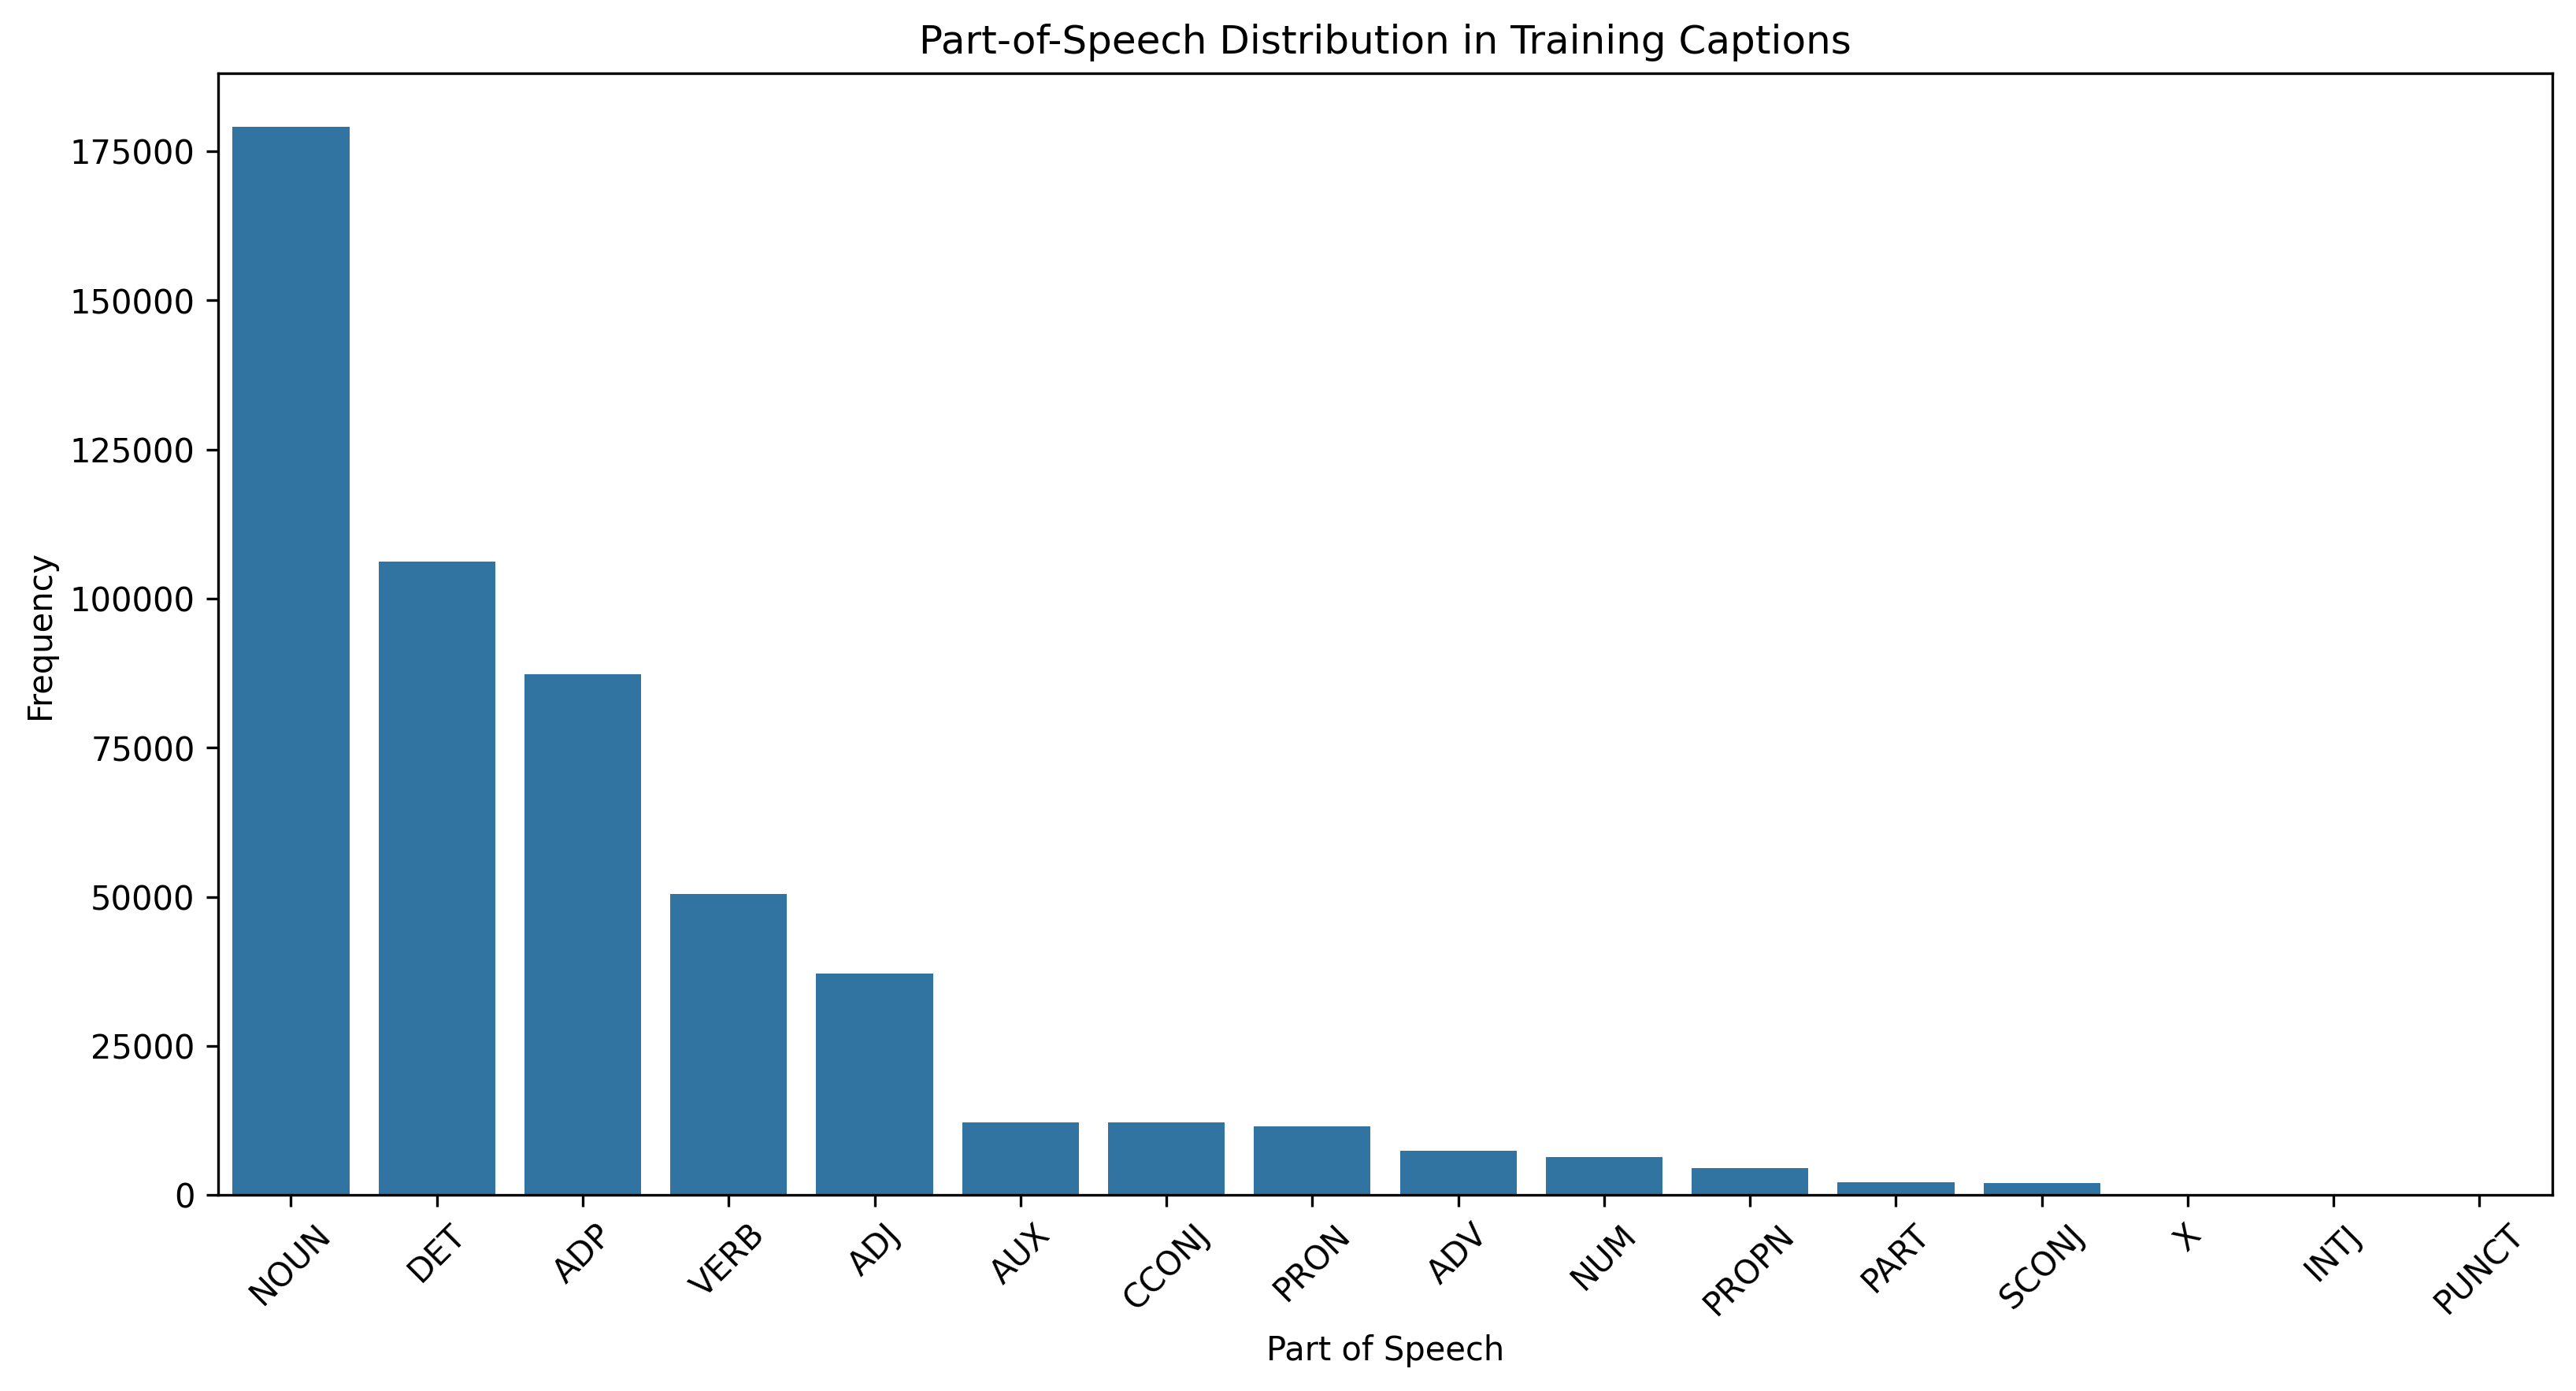

In [16]:
from IPython.display import display, Image

figures_to_inspect = [
    "top_50_object_classes.png",
    "objects_per_image_distribution.png",
    "caption_length_distribution.png",
    "top_30_frequent_words.png",
    "pos_distribution.png",
]

for filename in figures_to_inspect:
    figure_path = FIGURES_DIR / filename

    print(f"\nFigure: {filename}")

    display(
        Image(filename=str(figure_path))
    )

In [17]:
from datetime import datetime, timezone

# --------------------------------------------------
# 1. Define QC results
# --------------------------------------------------

qc_results = {
    "report_version": "1.0",
    "project": "MS-COCO Image Captioning Knowledge Base",
    "dataset": "MS-COCO 2017",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "overall_status": "passed_with_pending_validation",

    "dataset": {
        "training_images": len(training_set),
        "validation_images": len(validation_set),
        "test_images": len(test_set),
        "training_captions": len(caption_documents),
        "captions_per_image": 5,
        "random_seed": 45
    },

    "embeddings": {
        "clip": {
            "model": "openai/clip-vit-base-patch32",
            "vectors": int(clip_embeddings.shape[0]),
            "dimension": int(clip_embeddings.shape[1]),
            "dtype": str(clip_embeddings.dtype),
            "nan_values": int(np.isnan(clip_embeddings).sum()),
            "infinite_values": int(np.isinf(clip_embeddings).sum()),
            "zero_vectors": int(
                np.sum(np.linalg.norm(clip_embeddings, axis=1) == 0)
            ),
            "normalized": True,
            "status": "passed"
        },
        "sbert": {
            "model": "sentence-transformers/all-MiniLM-L6-v2",
            "vectors": int(sbert_embeddings.shape[0]),
            "dimension": int(sbert_embeddings.shape[1]),
            "dtype": str(sbert_embeddings.dtype),
            "nan_values": int(np.isnan(sbert_embeddings).sum()),
            "infinite_values": int(np.isinf(sbert_embeddings).sum()),
            "zero_vectors": int(
                np.sum(np.linalg.norm(sbert_embeddings, axis=1) == 0)
            ),
            "normalized": True,
            "status": "passed"
        }
    },

    "quality_checks": {
        "required_artifacts": "passed",
        "embedding_integrity": "passed",
        "mapping_uniqueness_and_alignment": "passed",
        "embedding_document_consistency": "passed",
        "image_caption_relationships": "passed",
        "dataset_leakage_audit": "passed",
        "faiss_index_integrity": "passed",
        "metadata_manifest_consistency": "passed",
        "statistical_artifacts": "passed",
        "visual_inspection": "passed"
    },

    "relationship_statistics": {
        "image_documents": len(image_documents),
        "caption_documents": len(caption_documents),
        "total_caption_references": len(all_referenced_caption_ids),
        "unique_caption_references": len(referenced_caption_ids),
        "unreferenced_captions": len(unreferenced_captions),
        "duplicate_caption_references": duplicate_references
    },

    "leakage_audit": {
        "training_validation_overlap": len(training_validation_overlap),
        "training_test_overlap": len(training_test_overlap),
        "validation_test_overlap": len(validation_test_overlap),
        "validation_images_in_knowledge_base": len(kb_validation_overlap),
        "test_images_in_knowledge_base": len(kb_test_overlap),
        "non_training_images_in_knowledge_base": len(kb_non_training_ids),
        "status": "passed"
    },

    "faiss_indexes": {
        "clip": {
            "vectors": int(clip_index.ntotal),
            "dimension": int(clip_index.d),
            "metric": "Inner Product",
            "vectors_match_original": True,
            "status": "passed"
        },
        "sbert": {
            "vectors": int(sbert_index.ntotal),
            "dimension": int(sbert_index.d),
            "metric": "Inner Product",
            "vectors_match_original": True,
            "status": "passed"
        }
    },

    "statistical_outputs": {
        "figures_verified": len(required_figures),
        "statistics_files_verified": len(required_statistics),
        "tables_verified": len(required_tables),
        "visual_inspection": "passed"
    },

    "retrieval_validation": {
        "status": "pending",
        "reason": (
            "The retrieval pipeline has not yet been implemented. "
            "Validation will be performed in a later project phase."
        )
    }
}


# --------------------------------------------------
# 2. Save machine-readable JSON report
# --------------------------------------------------

QC_JSON_PATH = METADATA_DIR / "quality_control_report.json"

with open(QC_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(qc_results, f, indent=4, ensure_ascii=False)


# --------------------------------------------------
# 3. Generate human-readable Markdown report
# --------------------------------------------------

report_date = qc_results["generated_at_utc"]

markdown_report = f"""
# Knowledge Base Quality Control Report

## 1. General Information

| Property | Value |
|---|---|
| Project | MS-COCO Image Captioning Knowledge Base |
| Dataset | MS-COCO 2017 |
| Knowledge-base split | Training |
| Random seed | 45 |
| Report version | 1.0 |
| Generated at (UTC) | {report_date} |
| Overall status | Passed with pending validation |

## 2. Dataset Summary

| Dataset component | Count |
|---|---:|
| Training images | {len(training_set):,} |
| Validation images | {len(validation_set):,} |
| Test images | {len(test_set):,} |
| Training captions | {len(caption_documents):,} |
| Captions per training image | 5 |

## 3. Embedding Integrity

### 3.1 CLIP Image Embeddings

| Property | Result |
|---|---|
| Model | openai/clip-vit-base-patch32 |
| Number of vectors | {clip_embeddings.shape[0]:,} |
| Dimension | {clip_embeddings.shape[1]} |
| Data type | {clip_embeddings.dtype} |
| NaN values | {int(np.isnan(clip_embeddings).sum())} |
| Infinite values | {int(np.isinf(clip_embeddings).sum())} |
| Zero vectors | {int(np.sum(np.linalg.norm(clip_embeddings, axis=1) == 0))} |
| Normalization | L2 normalized |
| Status | PASSED |

### 3.2 SBERT Caption Embeddings

| Property | Result |
|---|---|
| Model | sentence-transformers/all-MiniLM-L6-v2 |
| Number of vectors | {sbert_embeddings.shape[0]:,} |
| Dimension | {sbert_embeddings.shape[1]} |
| Data type | {sbert_embeddings.dtype} |
| NaN values | {int(np.isnan(sbert_embeddings).sum())} |
| Infinite values | {int(np.isinf(sbert_embeddings).sum())} |
| Zero vectors | {int(np.sum(np.linalg.norm(sbert_embeddings, axis=1) == 0))} |
| Normalization | L2 normalized |
| Status | PASSED |

## 4. Mapping and Document Consistency

| Check | Result |
|---|---|
| Mapping uniqueness and row alignment | PASSED |
| Embedding-to-document consistency | PASSED |
| Image-caption relationships | PASSED |
| Image documents | {len(image_documents):,} |
| Caption documents | {len(caption_documents):,} |
| Total caption references | {len(all_referenced_caption_ids):,} |
| Unique caption references | {len(referenced_caption_ids):,} |
| Unreferenced captions | {len(unreferenced_captions):,} |
| Duplicate caption references | {duplicate_references:,} |

## 5. Dataset Leakage Audit

| Check | Number of overlaps |
|---|---:|
| Training-validation | {len(training_validation_overlap)} |
| Training-test | {len(training_test_overlap)} |
| Validation-test | {len(validation_test_overlap)} |
| Validation images in knowledge base | {len(kb_validation_overlap)} |
| Test images in knowledge base | {len(kb_test_overlap)} |
| Non-training images in knowledge base | {len(kb_non_training_ids)} |

**Result: PASSED.**

The knowledge base contains only training images and their associated captions.
Validation and test data are excluded.

## 6. FAISS Index Integrity

| Property | CLIP Image Index | SBERT Caption Index |
|---|---:|---:|
| Index type | IndexFlatIP | IndexFlatIP |
| Vector count | {clip_index.ntotal:,} | {sbert_index.ntotal:,} |
| Dimension | {clip_index.d} | {sbert_index.d} |
| Metric | Inner Product | Inner Product |
| Original vectors match | Yes | Yes |
| Status | PASSED | PASSED |

## 7. Metadata and Manifest

The knowledge-base metadata and manifest were checked against the actual artifacts.

- Dataset and split information: PASSED
- Index metadata: PASSED
- Document metadata: PASSED
- Data exclusion metadata: PASSED
- Manifest statistics: PASSED
- Artifact inventory and file sizes: PASSED

## 8. Statistical and Visualisation QC

| Artifact category | Verified files |
|---|---:|
| Figures | {len(required_figures)} |
| Statistical JSON files | {len(required_statistics)} |
| CSV tables | {len(required_tables)} |

Visual inspection of the principal figures was completed.

Result: PASSED.

## 9. Overall Quality Control Results

| QC category | Status |
|---|---|
| Required artifact verification | PASSED |
| Embedding integrity | PASSED |
| Mapping uniqueness and alignment | PASSED |
| Embedding-to-document consistency | PASSED |
| Image-caption relationships | PASSED |
| Dataset leakage audit | PASSED |
| FAISS index integrity | PASSED |
| Metadata and manifest consistency | PASSED |
| Statistical artifact verification | PASSED |
| Visual inspection | PASSED |

## 10. Pending Validation

### Retrieval Pipeline Validation

**Status: PENDING**

The retrieval pipeline has not yet been implemented. Therefore, its compatibility with the frozen knowledge-base release has not been tested.

Retrieval validation must be completed in a later project phase, once the retrieval pipeline is available.

## 11. Conclusion

All currently implemented knowledge-base quality-control checks have passed.

The embeddings, mappings, documents, FAISS indexes, metadata, manifest, dataset relationships, and leakage constraints have been verified.

The knowledge base is ready for the next development stage, subject to future retrieval-pipeline validation.
"""


# --------------------------------------------------
# 4. Save Markdown report
# --------------------------------------------------

QC_MD_PATH = METADATA_DIR / "quality_control_report.md"

with open(QC_MD_PATH, "w", encoding="utf-8") as f:
    f.write(markdown_report.strip() + "\n")


# --------------------------------------------------
# 5. Display saved report paths
# --------------------------------------------------

print("QC REPORTS GENERATED SUCCESSFULLY\n")

print("JSON report:")
print(QC_JSON_PATH)

print("\nMarkdown report:")
print(QC_MD_PATH)

print("\nOverall status:", qc_results["overall_status"])
print("Retrieval validation:", qc_results["retrieval_validation"]["status"])

QC REPORTS GENERATED SUCCESSFULLY

JSON report:
C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data\knowledge_base\metadata\quality_control_report.json

Markdown report:
C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data\knowledge_base\metadata\quality_control_report.md

Overall status: passed_with_pending_validation
Retrieval validation: pending


In [18]:
# Verify both reports exist
assert QC_JSON_PATH.exists()
assert QC_MD_PATH.exists()

# Reload JSON report
with open(QC_JSON_PATH, "r", encoding="utf-8") as f:
    saved_report = json.load(f)

# Verify essential information
assert saved_report["overall_status"] == "passed_with_pending_validation"

assert saved_report["dataset"]["training_images"] == TRAINING_SIZE
assert saved_report["dataset"]["validation_images"] == 100
assert saved_report["dataset"]["test_images"] == 100

assert saved_report["embeddings"]["clip"]["status"] == "passed"
assert saved_report["embeddings"]["sbert"]["status"] == "passed"

assert saved_report["leakage_audit"]["status"] == "passed"

assert saved_report["retrieval_validation"]["status"] == "pending"

# Verify Markdown content
markdown_content = QC_MD_PATH.read_text(encoding="utf-8")

assert "Knowledge Base Quality Control Report" in markdown_content
assert "Retrieval Pipeline Validation" in markdown_content
assert "PENDING" in markdown_content

print("JSON report verification: PASSED")
print("Markdown report verification: PASSED")
print("Retrieval validation correctly marked as pending.")

print("\nFINAL QC REPORT VERIFICATION: PASSED")

JSON report verification: PASSED
Markdown report verification: PASSED
Retrieval validation correctly marked as pending.

FINAL QC REPORT VERIFICATION: PASSED
